# **Aprendizaje Automático 1 - Trabajo Práctico 2**
## EDA - Predicción de lluvias en Australia

**Integrantes:** Alejandro Acosta, Diego Hauret, Gastón Rinaldi, Agustín Torres

Análisis exploratorio de datos previo a la construcción de un modelo de ...

**Indice:**
1. Carga y comprensión de los datos
2. Análisis de valores faltantes
3. Imputación de valores faltantes (ejemplo)
4. Análisis univariado (variable objetivo y predictoras)
5. Análisis bivariado (correlaciones y relación con MEDV)
6. Multicolinealidad entre predictoras
7. Detección de outliers
8. Conclusiones y próximos pasos


## Diccionario de variables

| Variable | Descripción |
| :--- | :--- |
| **Unnamed** | Índices |
| **Date** | Fecha |
| **Location** | Localidad de ubicación de la estación meteorológica |
| **MinTemp** | Temperatura mínima en °C |
| **MaxTemp** | Temperatura máxima en °C |
| **Rainfall** | Cantidad de lluvia registrada durante las últimas 24 horas (mm) |
| **Evaporation** | Evaporación aparente calculada (medida en mm) |
| **Sunshine** | Número de horas totales de sol brillante registradas a lo largo del día |
| **WindGustDir** | Dirección de la ráfaga de viento más fuerte |
| **WindGustSpeed** | Velocidad de la ráfaga de viento más fuerte |
| **WindDir9am** | Dirección del viento registrada a las 09:00 horas |
| **WindDir3pm** | Dirección del viento registrada a las 15:00 horas |
| **WindSpeed9am** | Velocidad del viento (en km/h). Promedio de los 10 minutos anteriores |
| **WindSpeed3pm** | Velocidad del viento (en km/h). Promedio de los 10 minutos anteriores |
| **Humidity9am** | Porcentaje de humedad relativa registrado a las 09:00 horas |
| **Humidity3pm** | Porcentaje de humedad relativa registrado a las 15:00 horas |
| **Pressure9am** | Presión atmosférica a las 09:00 horas (en hectopascales) |
| **Pressure3pm** | Presión atmosférica a las 15:00 horas (en hectopascales) |
| **Cloud9am** | Nubosidad a las 09:00 horas (0 indica cielo despejado y 8 nublado total) |
| **Cloud3pm** | Nubosidad a las 15:00 horas (0 indica cielo despejado y 8 nublado total) |
| **Temp9am** | Temperatura medida a las 09:00 horas en °C |
| **Temp3pm** | Temperatura medida a las 15:00 horas en °C |
| **RainToday** | Variable categórica binaria (Yes / No). Toma el valor Yes si la precipitación acumulada (Rainfall) en las últimas 24 horas superó el 1.0 mm |
| **RainTomorrow** | Variable objetivo (target) a predecir (Yes / No). Indica si lloverá al día siguiente (las precipitaciones de mañana superarán el umbral de 1.0 mm) |

## 0. Carga de librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

pd.set_option("display.max_columns", None)
pd.set_option('display.float_format', '{:.4f}'.format)

## 1. Carga y comprensión de los datos

In [2]:
df = pd.read_csv('weatherAUS_2026C2.csv')
print("Dimensiones:", df.shape)
df.head(10)


Dimensiones: (145412, 25)


,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6000,22.5000,0.6000,NaN,NaN,W,45.0000,W,WNW,19.0000,25.0000,68.8000,23.8000,1008.1000,1007.2000,8.0000,NaN,16.8000,20.8000,No,No,0.0000
1,1,2008-12-02,Albury,7.3000,25.8000,0.0000,NaN,NaN,WNW,44.0000,NNW,WSW,4.0000,23.0000,40.1000,22.1000,1011.1000,1007.5000,NaN,NaN,18.3000,24.6000,No,No,0.0000
2,2,2008-12-03,Albury,13.2000,26.2000,0.0000,NaN,NaN,WSW,46.0000,W,WSW,20.0000,27.0000,36.2000,31.5000,1007.3000,1009.4000,NaN,2.0000,21.2000,23.4000,No,No,0.0000
3,3,2008-12-04,Albury,10.0000,28.8000,0.0000,NaN,NaN,NE,23.0000,SE,E,10.0000,10.0000,45.8000,18.5000,1017.6000,1012.4000,NaN,NaN,17.4000,26.3000,No,No,1.0000
4,4,2008-12-05,Albury,17.4000,32.4000,1.0000,NaN,NaN,W,41.0000,ENE,NW,6.0000,17.0000,83.5000,34.6000,1010.9000,1005.9000,7.0000,8.0000,17.9000,29.1000,No,No,0.2000
5,5,2008-12-06,Albury,14.5000,30.1000,0.2000,NaN,NaN,WNW,55.0000,W,W,19.0000,24.0000,56.6000,23.0000,1009.9000,1005.5000,NaN,NaN,20.9000,28.2000,No,No,0.0000
6,6,2008-12-07,Albury,15.1000,25.3000,0.0000,NaN,NaN,W,51.0000,SW,W,21.0000,24.0000,46.8000,20.3000,1009.3000,1008.5000,1.0000,NaN,18.3000,24.0000,No,No,0.0000
7,7,2008-12-08,Albury,8.1000,26.1000,0.0000,NaN,NaN,W,34.0000,SSE,W,5.0000,16.0000,46.8000,20.8000,1013.5000,1009.7000,NaN,NaN,17.1000,25.9000,No,No,0.0000
8,8,2008-12-09,Albury,9.5000,31.8000,0.0000,NaN,NaN,NNW,80.0000,SE,NW,6.0000,28.0000,42.1000,8.5000,1008.9000,1003.6000,NaN,NaN,18.0000,28.9000,No,Yes,1.4000
9,9,2008-12-10,Albury,13.4000,30.1000,1.4000,NaN,NaN,W,28.0000,S,SSE,14.0000,12.0000,57.6000,24.6000,1007.2000,1005.7000,NaN,NaN,18.9000,28.2000,Yes,No,0.0000


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        145412 non-null  int64  
 1   Date              145412 non-null  str    
 2   Location          145412 non-null  str    
 3   MinTemp           143928 non-null  float64
 4   MaxTemp           144159 non-null  float64
 5   Rainfall          142152 non-null  float64
 6   Evaporation       82658 non-null   float64
 7   Sunshine          75616 non-null   float64
 8   WindGustDir       135096 non-null  str    
 9   WindGustSpeed     135159 non-null  float64
 10  WindDir9am        134850 non-null  str    
 11  WindDir3pm        141186 non-null  str    
 12  WindSpeed9am      143645 non-null  float64
 13  WindSpeed3pm      142351 non-null  float64
 14  Humidity9am       142759 non-null  float64
 15  Humidity3pm       140907 non-null  float64
 16  Pressure9am       130351 non-nu

In [5]:
df.describe().T
desc = df.describe().T

print('Estadísticos descriptivos:')
print('=' * 110)
desc


Estadísticos descriptivos:


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,145412.0000,72728.1844,41990.7222,0.0000,36362.7500,72727.5000,109093.2500,145458.0000
MinTemp,143928.0000,12.1965,6.4180,-9.7000,7.6000,12.0000,16.9000,34.1000
MaxTemp,144159.0000,23.2231,7.1359,-5.1000,17.9000,22.6000,28.2000,49.1000
Rainfall,142152.0000,2.3615,8.4793,0.0000,0.0000,0.0000,0.8000,371.0000
Evaporation,82658.0000,5.4686,4.1939,0.0000,2.6000,4.8000,7.4000,145.0000
Sunshine,75616.0000,7.6112,3.7856,0.0000,4.8000,8.4000,10.6000,14.5000
WindGustSpeed,135159.0000,40.0367,13.6483,6.0000,31.0000,38.0000,48.0000,135.0000
WindSpeed9am,143645.0000,14.0673,8.9368,0.0000,7.0000,13.0000,19.0000,130.0000
WindSpeed3pm,142351.0000,18.6619,8.8655,0.0000,12.0000,18.0000,24.0000,86.0000
Humidity9am,142759.0000,68.8615,19.0629,0.0000,57.0000,69.9000,83.1000,100.0000


In [6]:
print("Filas duplicadas:", df.duplicated().sum())


Filas duplicadas: 0


## 2. Análisis de valores faltantes


Revisamos cuántos nulos tiene cada columna y si hay algún patrón (filas con muchos nulos a la vez, o nulos concentrados).


In [7]:
faltante = df.isna().sum().sort_values(ascending=False)
faltante_pct = (faltante / len(df) * 100).round(2)
print("Cantidad de nulos por columna:")
pd.DataFrame({"nulos": faltante, "% nulos": faltante_pct})


Cantidad de nulos por columna:


,nulos,% nulos
Sunshine,69796,48.0000
Evaporation,62754,43.1600
Cloud3pm,59336,40.8100
Cloud9am,55870,38.4200
Pressure9am,15061,10.3600
Pressure3pm,15024,10.3300
WindDir9am,10562,7.2600
WindGustDir,10316,7.0900
WindGustSpeed,10253,7.0500
Humidity3pm,4505,3.1000


Se observa que las variables Sunshine, Evaporation, Cloud3pm y Cloud9am tienen más de 38% de valores faltantes. Esto representa demasiados valores como para imputar y tendremos que dropear esas columnas. El resto de las variables tienen menos de 10% de faltantes y son más manejables.
La variable target RainTomorrow tiene 3259 valores faltantes. Esos registros los tenemos que eliminar.

In [8]:
nulos_por_fila = df.isna().sum(axis=1)
print("Cantidad de nulos por fila:\n",nulos_por_fila.value_counts().sort_index())


Cantidad de nulos por fila:
 0     56412
1     10764
2     18167
3      9920
4     28702
5      3774
6     10432
7      2087
8      1440
9       500
10      388
11      717
12      797
13      130
14      550
15       62
16       82
17      123
18       65
19       23
20       85
21       10
22      182
Name: count, dtype: int64


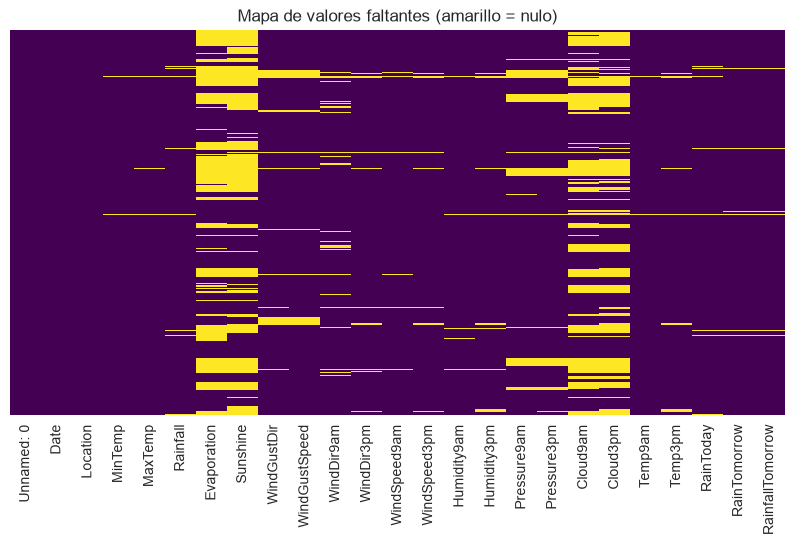

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False, cmap="viridis", yticklabels=False, ax=ax)
#cbar=False desactiva la barra lateral de medidas
#yticklabels=False oculta las etiquetas de valores del eje y
ax.set_title("Mapa de valores faltantes (amarillo = nulo)")
plt.show()


## 3. Análisis univariado



### 3.1 Variable objetivo: RainTomorrow

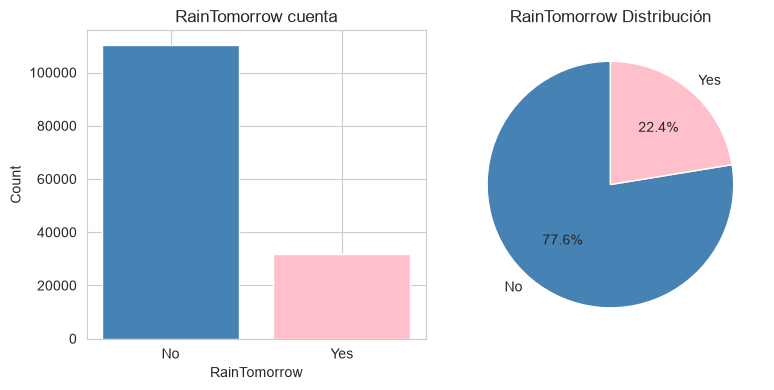

RainTomorrow
No    77.5800
Yes   22.4200
Name: proportion, dtype: float64


In [12]:
target_cant = df['RainTomorrow'].value_counts()
target_pct = df['RainTomorrow'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Diagrama de barras
axes[0].bar(target_cant.index, target_cant.values, color=['steelblue', 'pink'])
axes[0].set_title('RainTomorrow cuenta')
axes[0].set_xlabel('RainTomorrow')
axes[0].set_ylabel('Count')

# Diagrama de sectores
axes[1].pie(target_pct, labels=target_cant.index, autopct='%1.1f%%',
            colors=['steelblue', 'pink'], startangle=90)
axes[1].set_title('RainTomorrow Distribución')

plt.tight_layout()
plt.show()

print(target_pct.round(2))

### 3.2 Distribución de las predictoras

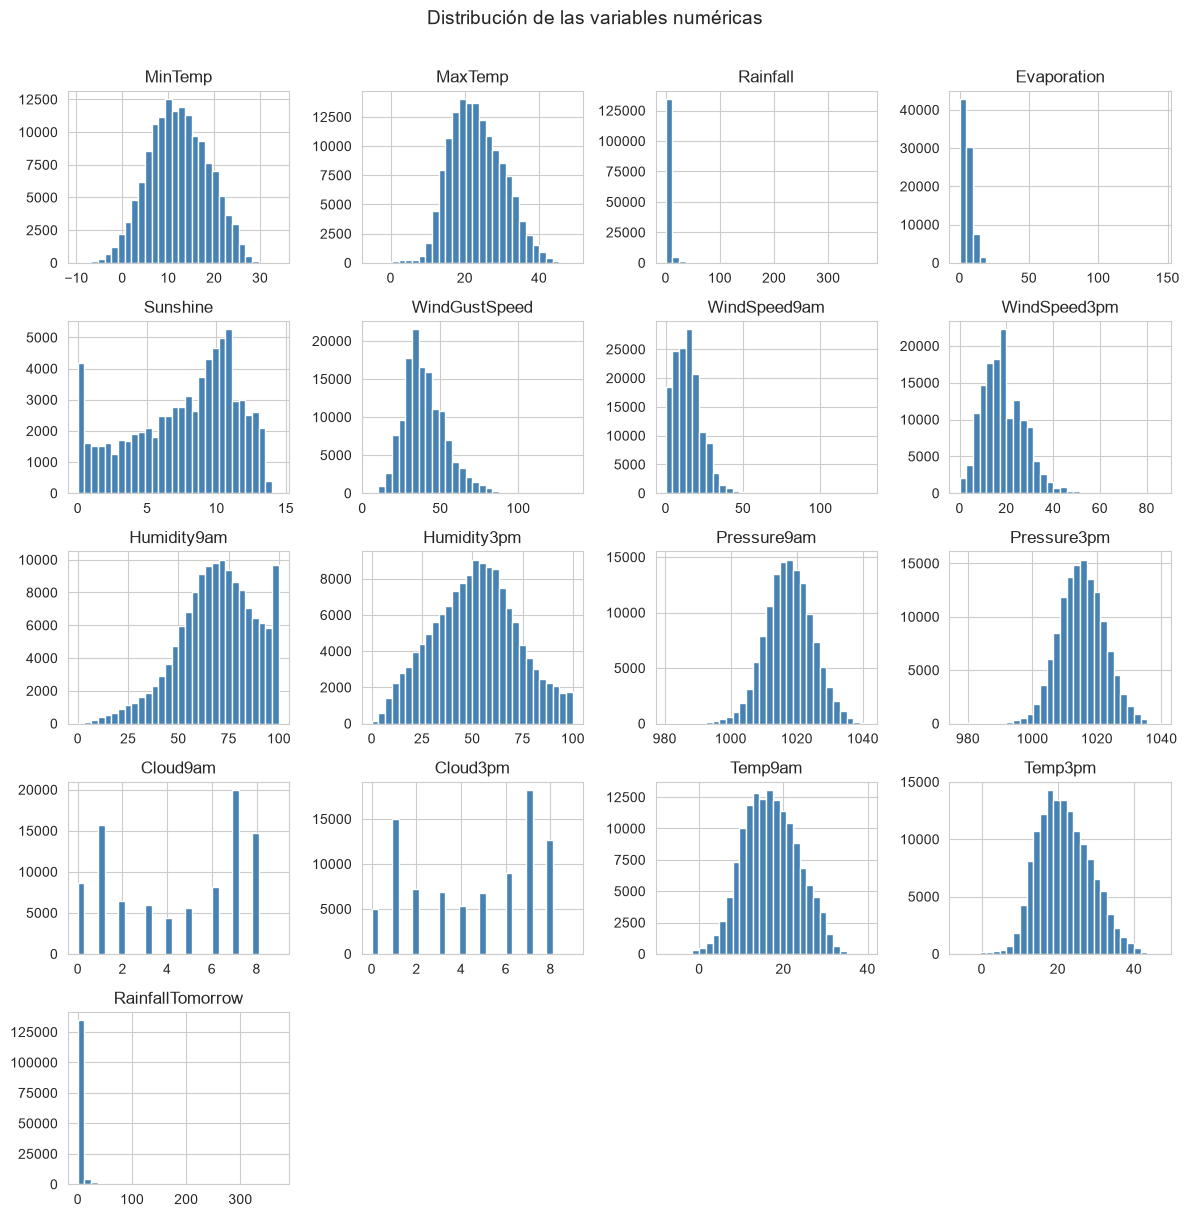

In [13]:
cols_num = df.select_dtypes(include='float64').columns.tolist()

df[cols_num].hist(figsize=(12, 12), bins=30, color='steelblue', edgecolor='white')
plt.suptitle('Distribución de las variables numéricas', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


Cloud9am y Cloud3pm muestran un patrón bimodal.

Rainfall y Evaporation están fuertemente sesgadas a la derecha.

Las características de temperatura y presión siguen una distribución cercana a la normal.

## 4. Análisis bivariado



### 4.1 Matriz de correlación

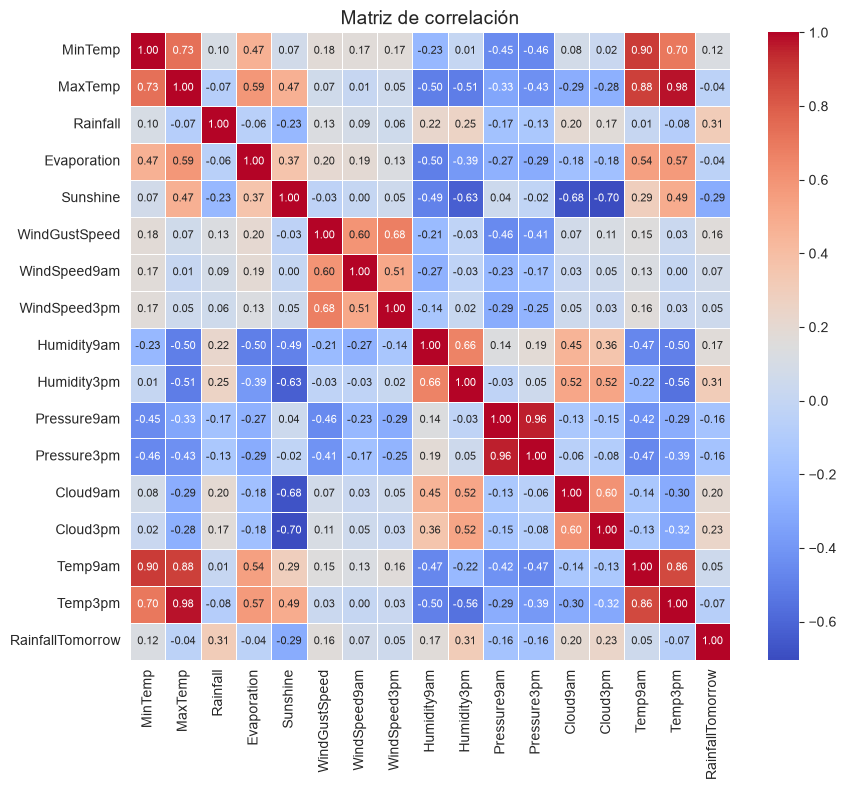

In [14]:
corr = df[cols_num].corr()
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, annot_kws={'size': 8})
ax.set_title("Matriz de correlación", fontsize=14)
plt.tight_layout()
plt.show()


Observndo el mapa de calor podemos ver algunas correlaciones fuertes entre las predictoras.

Pressure9am y Pressure3pm están correlacionadas en 0.96, casi perfectamente redundantes, así que mantendremos solo una.

Temp9am y Temp3pm muestran un comportamiento similar, con una correlación de 0,86.

### 4.2 Relación de las variables más correlacionadas con MEDV

## 5. Multicolinealidad entre predictoras


Calculamos el VIF (Variance Inflation Factor) de cada predictora usando regresiones lineales (sin depender de `statsmodels`). Un VIF alto (>5-10) sugiere redundancia entre variables.


## 6. Detección de outliers

Boxplots de todas las variables (estandarizadas para poder compararlas en la misma escala).


## 7. Conclusiones y próximos pasos del EDA


- **Variables más predictivas**: según la correlación con MEDV, probablemente RM y LSTAT.
- **Multicolinealidad**: variables con VIF alto (sección 5) — decidimos eliminar la variable TAX y RAD porque tienen un valor mayor a 5.
- **Estrategia de imputación**: definimos imputacion por mediana debido a la cantidad de outliers que podrían afectar el estudio  si usamos imputación por KNN.
- **Outliers**: podemos observar que los outliers no superan el 20% para cada variable.
- **Siguiente paso**: Separar train/validation/test, imputar valores faltantes, aplicar las transformaciones definidas y probar un primer modelo (regresión lineal) antes de pasar a modelos más complejos.
- Debido al desbalanceo observado en la variable CHAS, descartamos esta variable.
- Decidimos eliminar los registros con valores faltantes en la variable objetivo (MEDV) en item 2.

In [ ]:
df = df.drop(columns=['TAX','RAD'])

## 8. Separacion train/validation/test

In [ ]:
# El objetivo no puede contener NaN: eliminamos esas filas antes de separar los conjuntos.
df = df.dropna(subset=["MEDV"]).copy()

# Separación de los conjuntos de entrenamiento, validación y prueba
# Train: 60%, Validation: 20%, Test: 20%
X = df.drop(columns="MEDV")
y = df["MEDV"]
X_train_temp, X_test, y_train_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=15) #Antes 42 y 0.20
X_train, X_val, y_train, y_val = train_test_split(X_train_temp, y_train_temp, test_size=0.17647, random_state=15) #Antes 42 y 0.25
X_train.shape, X_val.shape, X_test.shape
X_train.head()
y_train.shape, y_val.shape, y_test.shape


((373,), (81,), (81,))

## 9. Imputación de valores faltantes y escalado de datos

# 16. Conclusiones finales (Punto 7)

1. **Análisis del Fitting**:
 Las métricas obtenidas entre entrenamiento y prueba resultan muy cercanas (por ejemplo,  R2≈0.56−0.57  en Train vs.  0.58−0.61  en Test), lo cual descarta la presencia de overfitting grave y confirma un buen fitting general, no obstante la perfomance general es baja.

2. **Desempeño de la Regularización**: Los resultados de Ridge y ElasticNet son prácticamente equivalentes en este experimento.
No sería correcto decir que ElasticNet es "muchísimo mejor" que Ridge. Lo que podemos decir es que en este conjunto Test obtuvo valores ligeramente mejores.

3. Ridge y ElasticNet obtuvieron valores de R², RMSE y MAE en Test muy similares, y superiores a los obtenidos por OLS y Lasso. ElasticNet presentó los mejores valores de las tres métricas evaluadas sobre Test, aunque la diferencia respecto de Ridge fue pequeña.
